# CAN 주행 로그 기반 급제동 탐지 — 데이터·모델 노트북

**목표**: 2분짜리 주행 클립의 차량 센서(CAN) 기록만 보고, 그 안에 **급제동(급감속·급정지)**이 있었는지 맞히는 모델을 직접 학습한다.

**데이터**: AI Hub 「사고위험 환경에서의 운전습관 데이터」(2024, 에이아이웍스 외)

**이 노트북이 하는 일** (위에서 아래로 순서대로 실행)

| 단계 | 내용 | 평가표 |
|---|---|---|
| 1 | 환경 준비, 데이터 위치 확인 | – |
| 2 | 라벨 표 만들기, 클래스 분포 | B1 |
| 3 | CAN 파일 구조 확인 | B1 |
| 4 | 전처리 5가지 + 전후 비교 | B2 |
| 5 | 전체 클립 특징 추출 | B2 |
| 6 | 운전자 단위 train/val/test 분할 | B3 |
| 7 | 모델 3개 학습 + 학습 로그, 최종 모델 선택 | C1, C2 |
| 8 | 테스트셋 평가, 비교표 | C3 |
| 9 | 혼동행렬·ROC·학습곡선·오류 사례 | C4 |
| 10 | 최종 모델 저장 + 다시 불러와 검증 | D1 |
| 11 | (선택) 실제 도로 클립에 적용, 지름길 학습 확인 | 분석 자료 |

**Colab 준비물**: 구글 드라이브에 `ml-final/data` 폴더를 만들고 AI Hub에서 받은 zip을 **압축을 풀지 말고 그대로** 올린다.

- 필수 (약 150MB): `TL_`로 시작하는 라벨 zip 5개, `TS_차대차및차량단독_CAN 데이터.zip`, `TS_차대사람및차대자전거_CAN 데이터.zip`
- 선택 (약 1.15GB, 11단계용): `TS_사고다발구간_CAN 데이터.zip`, `TS_사고위험구간_CAN 데이터.zip`, `TS_기타구간_CAN 데이터.zip`

## 1. 환경 준비

필요한 라이브러리를 불러오고, 데이터 폴더와 결과 저장 폴더를 정한다. Colab이면 구글 드라이브를 연결하고, 내 컴퓨터(VS Code)면 `~/ml-final` 폴더를 쓴다.

In [1]:
import json, os, re, sys, time, zipfile, unicodedata, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, joblib

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, log_loss, confusion_matrix, roc_curve,
                             ConfusionMatrixDisplay)

SEED = 42
np.random.seed(SEED)

try:
    from google.colab import drive          # Colab에서만 존재
    drive.mount("/content/drive")
    PROJECT = Path("/content/drive/MyDrive/ml-final")
except ImportError:                          # VS Code 등 로컬 실행
    PROJECT = Path(os.environ.get("ML_FINAL_DIR", Path.home() / "ml-final"))

DATA_DIR = Path(os.environ.get("ML_FINAL_DATA", PROJECT / "data"))   # zip을 올려둔 곳
OUT_DIR = PROJECT / "outputs"                                        # 결과가 저장될 곳
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

LOG_PATH = OUT_DIR / "train_log.txt"
LOG_PATH.write_text("", encoding="utf-8")

def log(msg=""):
    """화면에 출력하면서 train_log.txt에도 남긴다 (학습 로그 보존용)."""
    print(msg)
    with open(LOG_PATH, "a", encoding="utf-8") as f:
        f.write(str(msg) + "\n")

print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__)
print("데이터 폴더:", DATA_DIR, "| 존재:", DATA_DIR.exists())
print("결과 폴더  :", OUT_DIR)

Mounted at /content/drive
Python 3.13.18 | numpy 2.4.6 | pandas 2.2.3 | scikit-learn 1.6.1
데이터 폴더: /content/drive/MyDrive/ml-final/data | 존재: True
결과 폴더  : /content/drive/MyDrive/ml-final/outputs


### 1-1. 올려둔 zip 확인

데이터 폴더에서 zip을 찾아 라벨(`TL_`)과 CAN 센서(`TS_`)로 나누고, 안에 든 JSON 개수를 센다. macOS에서 올린 한글 파일명은 자모가 분리돼 있을 수 있어 `nfc()`로 통일한다.

In [2]:
def nfc(s):
    return unicodedata.normalize("NFC", str(s))

def section_of(zip_path):
    """'TS_차대차및차량단독_CAN 데이터.zip' -> '차대차및차량단독'"""
    name = nfc(Path(zip_path).stem)
    name = re.sub(r"^(TS_|TL_)", "", name)
    name = re.sub(r"_CAN.*$", "", name)
    return name.strip()

def json_members(zip_path):
    with zipfile.ZipFile(zip_path) as z:
        return [n for n in z.namelist() if n.lower().endswith(".json")]

label_zips, can_zips = {}, {}
for p in sorted(DATA_DIR.rglob("*.zip"), key=lambda x: nfc(x.name)):
    name = nfc(p.name)
    if name.startswith("TL_"):
        label_zips[section_of(p)] = p
    elif name.startswith("TS_"):
        can_zips[section_of(p)] = p

print(f"{'구간':<14}{'라벨 JSON':>10}{'CAN JSON':>10}")
for sec in sorted(set(label_zips) | set(can_zips)):
    n_lab = len(json_members(label_zips[sec])) if sec in label_zips else 0
    n_can = len(json_members(can_zips[sec])) if sec in can_zips else 0
    print(f"{sec:<14}{n_lab:>10}{n_can:>10}")

REQUIRED = ["차대차및차량단독", "차대사람및차대자전거"]
missing = [s for s in REQUIRED if s not in label_zips or s not in can_zips]
assert not missing, f"필수 zip이 없습니다: {missing} -> {DATA_DIR} 에 TL_/TS_ zip을 올려주세요."
print("\n필수 파일 확인 완료")

구간               라벨 JSON  CAN JSON
기타구간                   7         0
사고다발구간               963         0
사고위험구간              1347         0
차대사람및차대자전거            79        79
차대차및차량단독             244       244

필수 파일 확인 완료


## 2. 라벨 표 만들기

라벨 JSON에는 사람이 클립을 보고 적은 요약 문장(`SEN_5`)이 있다. 여기서 "차는 급감속한 적이 있다" 같은 표현을 찾아 거동 종류(`event`)를 뽑는다.

- `event`: 급감속 / 급정지 / 급출발 / 급가속 / 일반(해당 표현 없음)
- `label = 1`: **급제동** = 내 차가 급감속 또는 급정지를 함
- `label = 0`: 그 외 (일반, 급출발, 급가속)

"앞차는 급감속 중이다"처럼 **앞차** 얘기인 문장은 내 차의 거동이 아니므로 제외한다. 급출발·급가속을 정답에서 뺀 이유는 2-1에서 설명한다.

In [3]:
EVENT_RE = re.compile(r"(?<!앞)(?:차|차량)[은는] (급감속|급정지|급출발|급가속)")
BRAKE_EVENTS = ["급감속", "급정지"]

rows = []
for sec, zp in label_zips.items():
    with zipfile.ZipFile(zp) as z:
        for name in json_members(zp):
            d = json.loads(z.read(name).decode("utf-8-sig"))
            sen5 = d["labeling"]["SEN_5"]
            m = EVENT_RE.search(sen5)
            rows.append({
                "clip_id": Path(name).stem.split("_")[-1],
                "section": sec,
                "driver_id": d["Collection_info"]["Driver_ID"],
                "sex": d["Collection_info"]["Sex"],
                "age": d["Collection_info"]["Age"],
                "car": d["Collection_info"]["Car info"],
                "scenario": d["dataset"]["scenario"],      # Real=실제 도로, Test=테스트 도로
                "day_night": d["dataset"]["time"],
                "weather": d["dataset"]["weather"],
                "event": m.group(1) if m else "일반",
                "label": int(bool(m) and m.group(1) in BRAKE_EVENTS),
                "sen5": sen5,
            })

labels = pd.DataFrame(rows)
assert labels["clip_id"].is_unique
labels.to_csv(OUT_DIR / "labels.csv", index=False, encoding="utf-8-sig")

print("전체 라벨 수:", len(labels), "| 운전자 수:", labels["driver_id"].nunique())
print("\n[거동 종류]")
print(labels["event"].value_counts().to_string())
print("\n[수집 환경 x 거동 종류]  Real=실제 도로, Test=테스트 도로")
print(pd.crosstab(labels["scenario"], labels["event"]).to_string())

전체 라벨 수: 2640 | 운전자 수: 28

[거동 종류]
event
일반     2469
급감속      82
급출발      45
급정지      38
급가속       6

[수집 환경 x 거동 종류]  Real=실제 도로, Test=테스트 도로
event     급가속  급감속  급정지  급출발    일반
scenario                          
Real        0    0    0    0  2317
Test        6   82   38   45   152


### 2-1. 학습 범위와 정답 정하기

**① 테스트 도로 클립만 쓴다.** 위 표를 보면 급거동 표기는 테스트 도로(Test) 클립에만 있다. 실제 도로(Real) 클립은 한 건도 없는데, 정말 없었다기보다 표기 대상이 아니었을 가능성이 크다. 전체를 섞어 학습하면 모델이 "급제동"이 아니라 "테스트 도로인지"를 맞히게 된다(데이터 누수). 그래서 정답이 믿을 만한 테스트 도로 클립만 학습·평가에 쓰고, 실제 도로 클립은 11단계에서 정답 없는 데이터로 따로 다룬다.

**② 급제동(급감속·급정지)만 정답으로 삼는다.** 처음에는 급출발·급가속까지 묶어 "위험 거동" 전체를 맞히려 했다. 그런데 사전 점검에서 문제가 드러났다.

- 테스트 도로의 "일반" 클립은 대부분 정지 없이 계속 달리는 주행이고, "급출발" 클립은 정지 상태에서 출발한다. 그래서 트리 모델이 **"정지했다가 출발한 적이 있으면 위험"**이라는 지름길을 배웠다.
- 이 모델을 실제 도로 클립에 적용하니, 신호 대기 후 평범하게 출발한 클립까지 대거 위험으로 판정했다.
- 급출발 클립의 출발 세기는 실제 도로의 평범한 출발과 겹쳐서, 세기만으로는 구분되지 않았다.

반면 급제동은 감속도와 브레이크 압력이라는 **물리적 세기**로 드러난다. 그래서 정답을 급제동으로 좁히고, 특징도 제동 세기에 관한 것만 쓴다. 급출발·급가속 클립은 "급제동 없음(0)"으로 둔다. 이 지름길 현상은 11단계에서 직접 재현해 확인한다.

학습·평가 대상 클립 수: 323 | 운전자 수: 14

[클래스 분포]
  0 (급제동 없음): 203개 (62.8%)
  1 (급제동): 120개 (37.2%)

[구간별 x 거동]
event       급가속  급감속  급정지  급출발   일반
section                            
차대사람및차대자전거    0    3   15    9   52
차대차및차량단독      6   79   23   36  100

[운전자별 클립 수]
label      급제동 없음  급제동
driver_id             
000005          7    4
000011          6    1
000012         36   41
000016         12    0
000017         29    1
000018          6    5
000019          0    1
000020         41   20
000021         14    0
000025          8    1
000026          2    1
000027          6   21
000028         22    5
000029         14   19


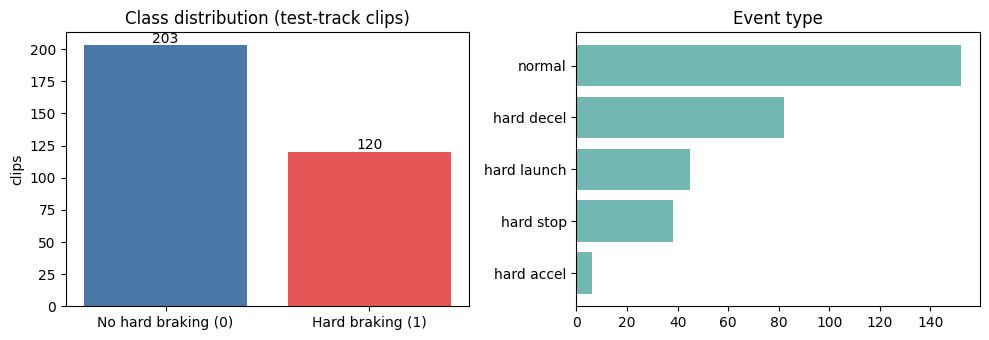

In [4]:
study = labels[labels["scenario"] == "Test"].copy().reset_index(drop=True)

print("학습·평가 대상 클립 수:", len(study), "| 운전자 수:", study["driver_id"].nunique())
print("\n[클래스 분포]")
dist = study["label"].value_counts().sort_index()
for k, v in dist.items():
    print(f"  {k} ({'급제동 없음' if k == 0 else '급제동'}): {v}개 ({v / len(study):.1%})")
print("\n[구간별 x 거동]")
print(pd.crosstab(study["section"], study["event"]).to_string())
print("\n[운전자별 클립 수]")
print(pd.crosstab(study["driver_id"], study["label"]).rename(columns={0: "급제동 없음", 1: "급제동"}).to_string())

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].bar(["No hard braking (0)", "Hard braking (1)"], dist.values, color=["#4C78A8", "#E45756"])
ax[0].set_title("Class distribution (test-track clips)")
ax[0].set_ylabel("clips")
for i, v in enumerate(dist.values):
    ax[0].text(i, v + 2, str(v), ha="center")
ev = study["event"].map({"일반": "normal", "급감속": "hard decel", "급정지": "hard stop",
                         "급출발": "hard launch", "급가속": "hard accel"}).value_counts()
ax[1].barh(ev.index[::-1], ev.values[::-1], color="#72B7B2")
ax[1].set_title("Event type")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_class_distribution.png", dpi=150)
plt.show()

## 3. CAN 파일 구조 확인

특징을 뽑기 전에 CAN 파일 한 개를 열어 어떤 값이 들어 있는지 확인한다.

In [5]:
# 클립 번호 -> (zip 경로, zip 안 파일명) 찾아보기 표
can_index = {}
for sec, zp in can_zips.items():
    for name in json_members(zp):
        can_index[Path(name).stem.split("_")[-1]] = (zp, name)

_zip_cache = {}
def read_frames(clip_id):
    """클립 번호로 CAN JSON을 읽어 프레임 목록을 돌려준다 (zip을 풀지 않고 바로 읽음)."""
    zp, name = can_index[clip_id]
    if zp not in _zip_cache:
        _zip_cache[zp] = zipfile.ZipFile(zp)
    return json.loads(_zip_cache[zp].read(name).decode("utf-8-sig"))["frames"]

study = study[study["clip_id"].isin(can_index.keys())].reset_index(drop=True)
print("CAN 파일이 있는 학습 대상 클립:", len(study))

sample_id = study.loc[study["event"] == "급감속", "clip_id"].iloc[0]
frames = read_frames(sample_id)
f0 = frames[len(frames) // 2]
print(f"\n예시 클립 {sample_id}: 프레임 {len(frames)}개")
print("프레임 한 개의 최상위 키:", list(f0.keys()))
print("\n[aim_micom] 차량 신호")
print({k: f0["aim_micom"][k] for k in ["gps_vss", "rpm_tick", "ad_brake", "brake_pressure",
                                       "steering_angle", "yawrate", "ad_turn_l", "ad_turn_r"]})
print("\n[aim_gsensor] 가속도·자이로 (H/L 바이트 제외)")
print({k: v for k, v in f0["aim_gsensor"].items() if not k.endswith(("H", "L"))})
print("\nfrm_time(ms):", f0["frm_time"], "| sys_time:", f0["sys_time"])

CAN 파일이 있는 학습 대상 클립: 323

예시 클립 02822: 프레임 3608개
프레임 한 개의 최상위 키: ['frameCnt', 'aim_gsensor', 'aim_micom', 'frm_time', 'gps', 'gps_info', 'sys_time']

[aim_micom] 차량 신호
{'gps_vss': 52, 'rpm_tick': 1234, 'ad_brake': 0, 'brake_pressure': 0, 'steering_angle': 0, 'yawrate': 0, 'ad_turn_l': 0, 'ad_turn_r': 0}

[aim_gsensor] 가속도·자이로 (H/L 바이트 제외)
{'accXAve': -1.0, 'accYAve': 77.0, 'accZAve': 5.0, 'angXAve': 0.0, 'angYAve': -16.0, 'angZAve': -1.0, 'gapOfAccXAve': -4051.0, 'gapOfAccYAve': -4037.0, 'gapOfAccZAve': 38.0, 'gapOfAngXAve': 81.0, 'gapOfAngYAve': 7, 'gapOfAngZAve': 21.0, 'pitch': 65061.0, 'roll': -3934.0, 'timestamp': 2059063, 'yaw': -3046.0}

frm_time(ms): 2055245 | sys_time: {'day': 26, 'hour': 7, 'minute': 17, 'month': 10, 'second': 2, 'year': 24}


**읽는 법**

- `gps_vss`: GPS 속도(km/h), `rpm_tick`: 엔진 회전수, `ad_brake`: 브레이크 등 켜짐(0/1), `brake_pressure`: 브레이크 압력
- 프레임은 1초에 약 30개씩 기록된다.
- `frm_time`은 클립 안에서의 시각(밀리초)이다.

## 4. 전처리

다섯 가지 전처리를 적용하고 각각 전후를 비교한다.

| # | 전처리 | 이유 |
|---|---|---|
| ① | 불량·불필요 컬럼 제거 | 값이 깨졌거나 항상 0인 센서는 학습에 방해 |
| ② | 30Hz → 1Hz·5Hz 리샘플링 | 같은 시각에 중복 기록된 프레임을 일정한 시간 간격으로 정리 |
| ③ | 결측 구간 보간 + 이상치 처리 | 기록이 끊긴 구간 때문에 생기는 가짜 급가속 제거 |
| ④ | 특징 생성 (5단계) | 2분 시계열을 모델이 쓸 수 있는 숫자 요약으로 변환 |
| ⑤ | 표준화 (6단계 분할 후) | 단위가 다른 특징의 크기를 맞춤 |

### ① 불량·불필요 컬럼 제거

학습 대상 클립 40개를 뽑아 센서별 값 분포를 본다.

                   min      1%  median      99%      max   unique
gps_vss            0.0     0.0    46.0     80.0     91.0     92.0
rpm_tick         515.0   675.0  1310.0   2426.0   3856.0   2093.0
ad_brake           0.0     0.0     0.0      1.0      1.0      2.0
brake_pressure     0.0     0.0     0.0     80.0    255.0    208.0
steering_angle     0.0     0.0     0.0      0.0      0.0      1.0
yawrate            0.0     0.0     0.0      0.0      0.0      1.0
accXAve         -408.8  -408.7    -4.3   6531.7   6539.9   1220.0
accYAve         -391.0  -332.0  -308.2    109.0    160.5    801.0
accZAve         -408.8  -408.6  -390.5     32.7   6539.9   1159.0
angZAve        -4088.0 -4087.0   -20.0    373.0  65399.0   1195.0
pitch          -4088.0 -4024.0  -866.0  65348.0  65399.0   4675.0
roll           -4088.0 -4070.0  -593.0  65377.0  65399.0   4733.0
yaw            -4088.0 -4007.0 -1339.0  63094.8  65399.0  16401.0


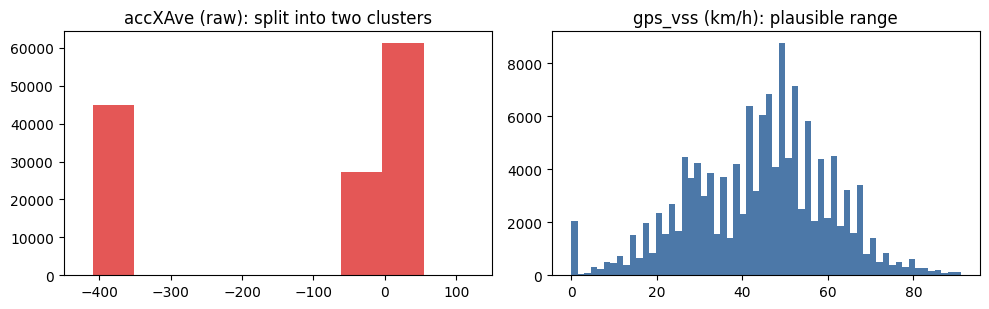


제거 전 후보 신호 13개 -> 제거 후 4개: ['gps_vss', 'rpm_tick', 'ad_brake', 'brake_pressure']


In [6]:
rng = np.random.RandomState(SEED)
probe_ids = rng.choice(study["clip_id"].values, size=min(40, len(study)), replace=False)

MICOM_KEYS = ["gps_vss", "rpm_tick", "ad_brake", "brake_pressure", "steering_angle", "yawrate"]
GSENSOR_KEYS = ["accXAve", "accYAve", "accZAve", "angZAve", "pitch", "roll", "yaw"]

probe = {k: [] for k in MICOM_KEYS + GSENSOR_KEYS}
for cid in probe_ids:
    for fr in read_frames(cid):
        for k in MICOM_KEYS:
            probe[k].append(fr["aim_micom"][k])
        for k in GSENSOR_KEYS:
            probe[k].append(fr["aim_gsensor"][k])

quality = pd.DataFrame({
    k: {"min": np.min(v), "1%": np.percentile(v, 1), "median": np.median(v),
        "99%": np.percentile(v, 99), "max": np.max(v), "unique": len(set(v))}
    for k, v in probe.items()
}).T.round(1)
print(quality.to_string())

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(probe["accXAve"], bins=120, color="#E45756")
ax[0].set_title("accXAve (raw): split into two clusters")
ax[0].set_xlim(-450, 150)
ax[1].hist(probe["gps_vss"], bins=60, color="#4C78A8")
ax[1].set_title("gps_vss (km/h): plausible range")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_sensor_quality.png", dpi=150)
plt.show()

KEEP = ["gps_vss", "rpm_tick", "ad_brake", "brake_pressure"]
print(f"\n제거 전 후보 신호 {len(MICOM_KEYS) + len(GSENSOR_KEYS)}개 -> 제거 후 {len(KEEP)}개: {KEEP}")

**판단**

- `steering_angle`, `yawrate`: 모든 값이 0이라 정보가 없다 → 제거
- `aim_gsensor` 계열: 값이 -400 부근과 0 부근 두 덩어리로 갈라지고 -4088, 65399 같은 값이 섞여 있다. 센서 값이 저장 과정에서 깨진 것으로 보이며 원래 값으로 되돌릴 근거가 없다 → 제거
- 위치(GPS 좌표)·날짜·시각: 장소와 촬영일을 외우는 누수 단서가 될 수 있다 → 사용하지 않음
- 남기는 신호: 속도, RPM, 브레이크 등, 브레이크 압력

### ② 리샘플링, ③ 결측 보간 + 이상치 처리

- **리샘플링**: `frm_time`을 기준으로 1초 단위로 묶어 속도·RPM은 평균, 브레이크는 최댓값을 쓴다. 순간적인 급제동은 1초 평균에 뭉개질 수 있어서, 속도와 브레이크 압력은 0.2초 단위(5Hz) 시계열도 함께 만든다.
- **결측 보간**: 기록이 끊겨 비어 있는 초는 앞뒤 값으로 직선 보간한다.
- **이상치 처리**: 1초에 +25km/h(약 0.7g)를 넘는 가속이나 -40km/h(약 1.1g)를 넘는 감속은 승용차의 물리적 한계 밖이므로 센서 오류로 본다. 특히 GPS가 늦게 잡히면 달리는 중인데도 속도가 0으로 찍히다가 갑자기 튀는데, 이때는 그 앞의 "가짜 정지" 구간까지 함께 지우고 다시 보간한다.

In [7]:
ACC_UP_LIMIT = 25.0     # 1초에 +25km/h (약 0.7g): 승용차가 낼 수 없는 가속 -> GPS 오류로 판단
ACC_DOWN_LIMIT = 40.0   # 1초에 -40km/h (약 1.1g): 타이어 마찰 한계를 넘는 감속 -> 센서 오류로 판단

def frames_to_raw(frames):
    """프레임 목록 -> 필요한 신호만 담은 표 (전처리 ①)."""
    return pd.DataFrame({
        "t_ms": [int(f["frm_time"]) for f in frames],
        "speed": [f["aim_micom"]["gps_vss"] for f in frames],
        "rpm": [f["aim_micom"]["rpm_tick"] for f in frames],
        "brake": [f["aim_micom"]["ad_brake"] for f in frames],
        "brake_pressure": [f["aim_micom"]["brake_pressure"] for f in frames],
    })

def resample_1hz(raw):
    """30Hz -> 1Hz (전처리 ②). 비어 있는 초는 NaN으로 남긴다."""
    sec = (raw["t_ms"] - raw["t_ms"].iloc[0]) // 1000
    g = raw.groupby(sec)
    s = pd.DataFrame({
        "speed": g["speed"].mean(),
        "rpm": g["rpm"].mean(),
        "brake": g["brake"].max(),
        "brake_pressure": g["brake_pressure"].max(),
    })
    return s.reindex(range(int(s.index.max()) + 1))

def clean_1hz(s):
    """결측 보간 + 물리 한계를 넘는 속도 튐 제거 (전처리 ③). 처리 건수도 함께 돌려준다."""
    s = s.copy()
    n_missing = int(s["speed"].isna().sum())
    s = s.interpolate(limit_direction="both")           # 빈 초를 앞뒤 값으로 직선 보간

    v = s["speed"].to_numpy(dtype=float).copy()
    dv = np.diff(v, prepend=v[0])
    n_outlier = 0
    for i in np.flatnonzero(dv > ACC_UP_LIMIT):         # 불가능한 급가속 = GPS가 늦게 잡힌 흔적
        j = i - 1
        while j >= 0 and v[j] <= 1.0:                   # 그 직전까지 0으로 찍힌 구간은 가짜 정지
            v[j] = np.nan
            n_outlier += 1
            j -= 1
        if j == i - 1:                                  # 0 구간이 없으면 튄 지점만 지움
            v[i] = np.nan
            n_outlier += 1
    for i in np.flatnonzero(dv < -ACC_DOWN_LIMIT):      # 불가능한 급감속
        v[i] = np.nan
        n_outlier += 1
    if n_outlier:
        s["speed"] = v
        s = s.interpolate(limit_direction="both")
    s["brake"] = s["brake"].round().clip(0, 1)
    return s, {"n_missing_sec": n_missing, "n_outlier_sec": n_outlier}

def resample_5hz(raw):
    """0.2초 단위 시계열. 1초 평균으로는 뭉개지는 순간적인 급제동을 잡기 위해 쓴다."""
    t = raw["t_ms"] - raw["t_ms"].iloc[0]
    g = raw.groupby(t // 200)
    s = pd.DataFrame({"speed": g["speed"].mean(), "brake_pressure": g["brake_pressure"].max()})
    return s.reindex(range(int(s.index.max()) + 1)).interpolate(limit_direction="both")

def preprocess_frames(frames):
    """프레임 목록 -> (1Hz 시계열, 5Hz 시계열, 처리 정보). 서비스에서도 이 함수를 그대로 쓴다."""
    raw = frames_to_raw(frames)
    s1, info = clean_1hz(resample_1hz(raw))
    s5 = resample_5hz(raw)
    info["n_frames"] = len(raw)
    info["n_seconds"] = len(s1)
    return s1, s5, info

# ---- 전후 비교: 예시 클립 한 개 ----
raw = frames_to_raw(read_frames(sample_id))
res = resample_1hz(raw)
cln, info = clean_1hz(res)
print(f"[클립 {sample_id}]")
print(f"  ② 리샘플링  : {len(raw)}행 (그중 같은 시각 중복 {int((raw['t_ms'].diff() == 0).sum())}행) -> {len(res)}행")
print(f"  ③ 결측/이상치: 결측 {info['n_missing_sec']}초, 이상치 {info['n_outlier_sec']}초")

[클립 02822]
  ② 리샘플링  : 3608행 (그중 같은 시각 중복 2822행) -> 121행
  ③ 결측/이상치: 결측 0초, 이상치 0초


전체 학습 대상 클립에 ②③을 적용하고, 결측·이상치가 있던 클립이 처리 전후로 어떻게 달라지는지 본다.

  100/323 클립 처리 (23초)
  200/323 클립 처리 (40초)
  300/323 클립 처리 (56초)
  323/323 클립 처리 (59초)

[② 리샘플링 전후]
  전체 행 수: 1,119,343 -> 37,578  (클립당 중앙값 3579 -> 120)

[③ 결측·이상치 처리]
  결측 초가 있던 클립: 3개, 보간한 초: 50초
  물리 한계를 넘는 튐이 있던 클립: 1개, 고친 초: 23초

  처리 대상 클립의 전후 비교
         결측 초  이상치 초  전: 값 있는 초  후: 값 있는 초  전: 최대 가속(km/h/s)  후: 최대 가속(km/h/s)
clip_id                                                                       
03081      17      0        128        145               6.2               6.2
02811      18      0         94        112              10.6              10.6
03122      15     23        117        132              29.6               5.2


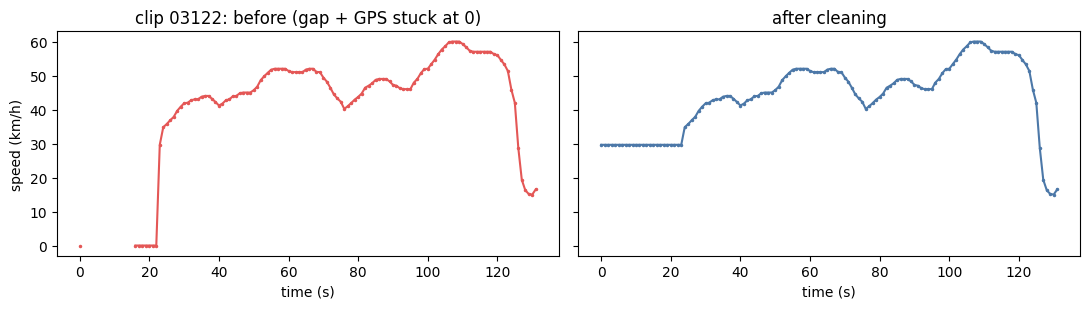

In [8]:
t0 = time.time()
series = {}          # clip_id -> 깨끗한 1Hz 시계열
series5 = {}         # clip_id -> 5Hz 시계열
before_series = {}   # 결측·이상치가 있던 클립의 처리 전 시계열 (비교용)
prep_rows = []
for i, cid in enumerate(study["clip_id"]):
    raw = frames_to_raw(read_frames(cid))
    res = resample_1hz(raw)
    cln, info = clean_1hz(res)
    series[cid] = cln
    series5[cid] = resample_5hz(raw)
    prep_rows.append({"clip_id": cid, "frames": len(raw), "seconds": len(cln),
                      "missing_sec": info["n_missing_sec"], "outlier_sec": info["n_outlier_sec"]})
    if info["n_missing_sec"] or info["n_outlier_sec"]:
        before_series[cid] = res
    if (i + 1) % 100 == 0 or i + 1 == len(study):
        print(f"  {i + 1}/{len(study)} 클립 처리 ({time.time() - t0:.0f}초)")

prep = pd.DataFrame(prep_rows).set_index("clip_id")
print("\n[② 리샘플링 전후]")
print(f"  전체 행 수: {prep['frames'].sum():,} -> {prep['seconds'].sum():,}  (클립당 중앙값 {prep['frames'].median():.0f} -> {prep['seconds'].median():.0f})")
print("\n[③ 결측·이상치 처리]")
print(f"  결측 초가 있던 클립: {(prep['missing_sec'] > 0).sum()}개, 보간한 초: {prep['missing_sec'].sum()}초")
print(f"  물리 한계를 넘는 튐이 있던 클립: {(prep['outlier_sec'] > 0).sum()}개, 고친 초: {prep['outlier_sec'].sum()}초")

cmp_rows = []
for cid, res in before_series.items():
    b = res["speed"].dropna()                      # 처리 전: 빈 초를 그냥 건너뛴 상태
    a = series[cid]["speed"]
    cmp_rows.append({"clip_id": cid, "결측 초": prep.loc[cid, "missing_sec"], "이상치 초": prep.loc[cid, "outlier_sec"],
                     "전: 값 있는 초": len(b), "후: 값 있는 초": len(a),
                     "전: 최대 가속(km/h/s)": b.diff().max(), "후: 최대 가속(km/h/s)": a.diff().max()})
if cmp_rows:
    print("\n  처리 대상 클립의 전후 비교")
    print(pd.DataFrame(cmp_rows).set_index("clip_id").round(1).to_string())

    worst = (prep["missing_sec"] + prep["outlier_sec"]).idxmax()
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
    ax[0].plot(before_series[worst].index, before_series[worst]["speed"], ".-", ms=3, color="#E45756")
    ax[0].set_title(f"clip {worst}: before (gap + GPS stuck at 0)")
    ax[1].plot(series[worst].index, series[worst]["speed"], ".-", ms=3, color="#4C78A8")
    ax[1].set_title("after cleaning")
    for x_ in ax:
        x_.set_xlabel("time (s)")
    ax[0].set_ylabel("speed (km/h)")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "03_cleaning_before_after.png", dpi=150)
    plt.show()

## 5. 특징 생성 (전처리 ④)

모델은 길이가 제각각인 시계열을 그대로 받을 수 없다. 그래서 클립마다 "가장 세게 감속한 정도", "브레이크 압력이 0.2초 만에 얼마나 올랐나"처럼 **제동 세기를 나타내는 숫자 요약**을 만든다.

- 모델 입력(`FEATURES`): 감속 세기, 브레이크 압력, 가장 센 제동 구간, 엔진 회전수 급락
- 모델에 넣지 않는 값: 클립 길이, 위치, 날짜, 평균 속도, 정지 비율, 출발 세기. 운전 방식이 아니라 주행 환경을 나타내서 지름길이 될 수 있다. 이 중 일부는 `ctx_` 이름으로 계산만 해 두고 11단계 분석에 쓴다.

④ 특징 생성: 클립당 약 120초 분량 시계열 -> 모델 입력 특징 19개 (+ 분석용 맥락 값 4개)
결측값 수: 0

[클래스별 특징 중앙값] (차이가 클수록 구분에 도움이 됨)
label           급제동 없음     급제동
acc_min          -2.35   -4.28
dec_06s_min      -4.17   -7.41
jerk_min         -1.37   -2.54
hard_decel_sec    0.00    1.00
bp_max           87.00  191.00
bp_rise_06s      66.00  123.00
bp_sec_over100    0.00    1.40
ep_speed_drop    25.24   39.00
rpm_drop_max    389.54  430.56

[거동 종류별 중앙값]
       acc_min  dec_06s_min  bp_max  bp_sec_over100
event                                              
급가속      -2.67        -5.56   187.0             0.9
급감속      -4.44        -7.41   192.5             1.4
급정지      -3.49        -6.48   189.0             1.5
급출발      -2.50        -4.63   109.0             0.4
일반       -2.33        -3.71    70.0             0.0


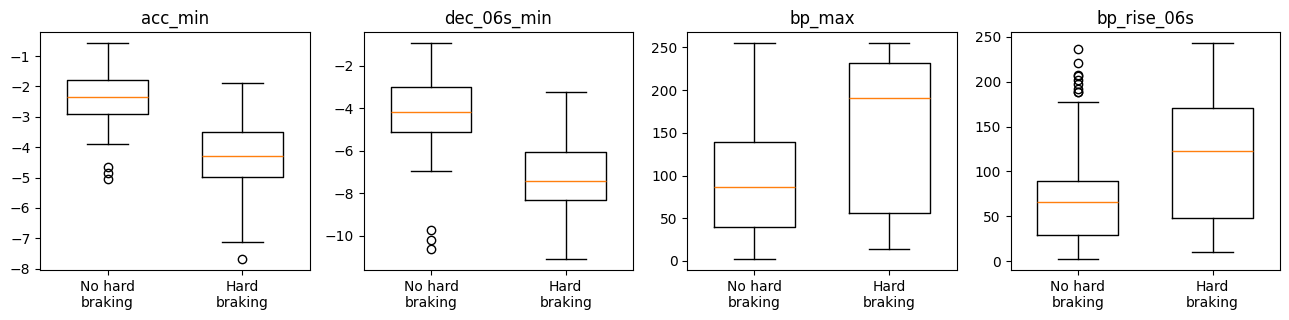

In [9]:
def _safe(fn, arr, default=0.0):
    return float(fn(arr)) if len(arr) else default

def extract_features(s1, s5):
    """깨끗한 시계열 -> 특징 딕셔너리. 서비스에서도 이 함수를 그대로 쓴다."""
    v = s1["speed"].to_numpy(dtype=float)              # km/h, 1초 간격
    rpm = s1["rpm"].to_numpy(dtype=float)
    brake = s1["brake"].to_numpy(dtype=float)
    bp1 = s1["brake_pressure"].to_numpy(dtype=float)
    acc = np.diff(v) / 3.6                             # m/s^2
    jerk = np.diff(acc)                                # m/s^3
    acc2 = (v[2:] - v[:-2]) / 3.6 / 2                  # 2초 평균 가속도

    v5 = s5["speed"].to_numpy(dtype=float)             # 0.2초 간격
    bp5 = s5["brake_pressure"].to_numpy(dtype=float)
    dec06 = (v5[3:] - v5[:-3]) / 3.6 / 0.6             # 0.6초 구간 가속도
    dec10 = (v5[5:] - v5[:-5]) / 3.6                   # 1.0초 구간 가속도
    limit = -ACC_DOWN_LIMIT / 3.6
    dec06 = dec06[dec06 >= limit]                      # 물리 한계를 넘는 값은 센서 오류로 보고 제외
    dec10 = dec10[dec10 >= limit]
    bp_roll3 = pd.Series(bp5).rolling(15, min_periods=1).mean().to_numpy()

    # 브레이크를 밟고 있던 구간(에피소드) 중 가장 세게 감속한 구간
    ep = {"ep_speed_drop": 0.0, "ep_mean_decel": 0.0, "ep_pressure_peak": 0.0, "ep_speed_at_onset": 0.0}
    peak, i, n = 0.0, 0, len(v)
    while i < n:
        if brake[i] > 0:
            j = i
            while j + 1 < n and brake[j + 1] > 0:
                j += 1
            start = max(i - 1, 0)
            seg = np.diff(v[start:j + 1])
            pk = -seg.min() / 3.6 if len(seg) else 0.0
            if pk > peak:
                peak = pk
                ep = {"ep_speed_drop": v[start] - v[j],                          # 그 구간에서 줄인 속도(km/h)
                      "ep_mean_decel": (v[start] - v[j]) / 3.6 / (j - i + 1),    # 그 구간의 평균 감속
                      "ep_pressure_peak": bp1[i:j + 1].max(),                    # 그 구간의 최대 압력
                      "ep_speed_at_onset": v[start]}                             # 밟기 시작할 때 속도
            i = j + 1
        else:
            i += 1

    launch = (v[3:] - v[:-3])[v[:-3] <= 3]

    return {
        # --- 감속 세기 (1Hz) ---
        "acc_min": _safe(np.min, acc),                       # 1초 최대 감속
        "acc2s_min": _safe(np.min, acc2),                    # 2초 평균 최대 감속
        "acc_p05": _safe(lambda a: np.percentile(a, 5), acc),
        "jerk_min": _safe(np.min, jerk),                     # 감속이 얼마나 갑자기 시작됐나
        "hard_decel_sec": float((acc <= -3.0).sum()),        # -3m/s^2 이하로 감속한 시간(초)
        # --- 감속 세기 (5Hz) ---
        "dec_06s_min": _safe(np.min, dec06),                 # 0.6초 구간 최대 감속
        "dec_1s_min": _safe(np.min, dec10),                  # 1초 구간 최대 감속
        # --- 브레이크 압력 ---
        "bp_max": float(bp5.max()),
        "bp_p95": float(np.percentile(bp5, 95)),
        "bp_rise_02s": _safe(np.max, np.diff(bp5)),          # 0.2초 만에 오른 압력
        "bp_rise_06s": _safe(np.max, bp5[3:] - bp5[:-3]),    # 0.6초 만에 오른 압력
        "bp_sec_over100": float((bp5 >= 100).sum() * 0.2),   # 압력 100 이상 유지 시간(초)
        "bp_sec_over150": float((bp5 >= 150).sum() * 0.2),
        "bp_top3s_mean": float(bp_roll3.max()),              # 가장 세게 밟은 3초의 평균 압력
        # --- 가장 센 제동 구간 ---
        **ep,
        # --- 엔진 ---
        "rpm_drop_max": _safe(lambda a: -np.min(a), np.diff(rpm)),
        # --- 맥락 값: 모델 입력으로는 쓰지 않고 11단계 분석에만 쓴다 ---
        "ctx_speed_mean": float(v.mean()),
        "ctx_stop_ratio": float((v <= 1).mean()),
        "ctx_acc_max": _safe(np.max, acc),
        "ctx_launch_dv3_max": max(_safe(np.max, launch), 0.0),   # 정지 상태에서 3초간 올린 속도
    }

FEATURES = ["acc_min", "acc2s_min", "acc_p05", "jerk_min", "hard_decel_sec", "dec_06s_min", "dec_1s_min",
            "bp_max", "bp_p95", "bp_rise_02s", "bp_rise_06s", "bp_sec_over100", "bp_sec_over150", "bp_top3s_mean",
            "ep_speed_drop", "ep_mean_decel", "ep_pressure_peak", "ep_speed_at_onset", "rpm_drop_max"]
CONTEXT = ["ctx_speed_mean", "ctx_stop_ratio", "ctx_acc_max", "ctx_launch_dv3_max"]

feat = pd.DataFrame([extract_features(series[cid], series5[cid]) for cid in study["clip_id"]],
                    index=study["clip_id"])
assert set(FEATURES + CONTEXT) == set(feat.columns)
data = study.set_index("clip_id").join(feat)
data.drop(columns=["sen5"]).to_csv(OUT_DIR / "features_study.csv", encoding="utf-8-sig")

print(f"④ 특징 생성: 클립당 약 {prep['seconds'].median():.0f}초 분량 시계열 -> 모델 입력 특징 {len(FEATURES)}개 (+ 분석용 맥락 값 {len(CONTEXT)}개)")
print("결측값 수:", int(feat.isna().sum().sum()))
print("\n[클래스별 특징 중앙값] (차이가 클수록 구분에 도움이 됨)")
show = ["acc_min", "dec_06s_min", "jerk_min", "hard_decel_sec", "bp_max", "bp_rise_06s",
        "bp_sec_over100", "ep_speed_drop", "rpm_drop_max"]
print(data.groupby("label")[show].median().round(2).T.rename(columns={0: "급제동 없음", 1: "급제동"}).to_string())
print("\n[거동 종류별 중앙값]")
print(data.groupby("event")[["acc_min", "dec_06s_min", "bp_max", "bp_sec_over100"]].median().round(2).to_string())

fig, axes = plt.subplots(1, 4, figsize=(13, 3.3))
for ax, col in zip(axes, ["acc_min", "dec_06s_min", "bp_max", "bp_rise_06s"]):
    ax.boxplot([data.loc[data.label == 0, col], data.loc[data.label == 1, col]], widths=0.6)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["No hard\nbraking", "Hard\nbraking"])
    ax.set_title(col)
plt.tight_layout()
plt.savefig(FIG_DIR / "04_feature_boxplots.png", dpi=150)
plt.show()

## 6. Train / Validation / Test 분할

같은 운전자의 클립이 학습과 테스트에 동시에 들어가면, 모델이 그 사람의 운전 버릇을 외워서 점수가 실제보다 높게 나온다. 그래서 **운전자 단위로** 나눈다.

- 목표 비율: Train 60% / Validation 20% / Test 20% (클립 수 기준)
- 방법: 클립이 많은 운전자부터 차례로, 그 시점에 목표 클립 수에서 가장 많이 모자란 세트에 배정한다. 클립 수가 같은 운전자끼리의 순서는 `seed=42` 난수로 정한다.
- 이 방식은 직접 구현한 것이라 라이브러리 버전이 달라도 항상 같은 분할이 나온다.
- 운전자마다 클립 수가 달라서 비율이 딱 떨어지지 않는다. 실제 비율은 아래에 출력한다.

In [10]:
X_all = data[FEATURES]
y_all = data["label"]
groups = data["driver_id"]

TARGET_RATIO = {"train": 0.6, "val": 0.2, "test": 0.2}

def split_by_driver(driver_ids, seed=SEED, ratio=TARGET_RATIO):
    """운전자 단위 분할. 반환값: {운전자 ID: 'train' | 'val' | 'test'}"""
    counts = driver_ids.value_counts()
    ids = sorted(counts.index)                                   # 항상 같은 출발 순서
    tie = np.random.RandomState(seed).rand(len(ids))             # 동률을 깨는 난수
    order = [d for _, _, d in sorted(zip([-counts[d] for d in ids], tie, ids))]
    target = {k: r * len(driver_ids) for k, r in ratio.items()}
    current = {k: 0 for k in ratio}
    assign = {}
    for d in order:
        s = max(target, key=lambda k: target[k] - current[k])    # 가장 많이 모자란 세트
        assign[d] = s
        current[s] += counts[d]
    return assign

driver_split = split_by_driver(groups)
data["split"] = groups.map(driver_split)

summary = data.groupby("split").agg(
    clips=("label", "size"), hard_brake=("label", "sum"), drivers=("driver_id", "nunique")
).loc[["train", "val", "test"]]
summary["ratio"] = (summary["clips"] / len(data)).round(3)
summary["hard_brake_rate"] = (summary["hard_brake"] / summary["clips"]).round(3)
print("[분할 결과]  seed =", SEED)
print(summary.to_string())

drv = {s: set(data.loc[data.split == s, "driver_id"]) for s in ["train", "val", "test"]}
overlap = (drv["train"] & drv["val"]) | (drv["train"] & drv["test"]) | (drv["val"] & drv["test"])
print("\n세트 간 겹치는 운전자 수:", len(overlap), "(0이어야 함)")
assert len(overlap) == 0
for s in ["train", "val", "test"]:
    print(f"  {s:<5} 운전자: {sorted(drv[s])}")

data[["driver_id", "label", "event", "split"]].to_csv(OUT_DIR / "split.csv", encoding="utf-8-sig")

X_train, y_train = data.loc[data.split == "train", FEATURES], data.loc[data.split == "train", "label"]
X_val, y_val = data.loc[data.split == "val", FEATURES], data.loc[data.split == "val", "label"]
X_test, y_test = data.loc[data.split == "test", FEATURES], data.loc[data.split == "test", "label"]

[분할 결과]  seed = 42
       clips  hard_brake  drivers  ratio  hard_brake_rate
split                                                    
train    192          72        7  0.594            0.375
val       65          25        4  0.201            0.385
test      66          23        3  0.204            0.348

세트 간 겹치는 운전자 수: 0 (0이어야 함)
  train 운전자: ['000005', '000012', '000016', '000019', '000020', '000026', '000028']
  val   운전자: ['000011', '000018', '000021', '000029']
  test  운전자: ['000017', '000025', '000027']


### ⑤ 표준화 (전후 비교)

특징마다 단위가 다르다(브레이크 압력은 수백, 가속도는 한 자릿수). Logistic Regression은 큰 숫자에 끌려가므로 평균 0, 표준편차 1로 맞춘다.

누수를 막기 위해 **평균과 표준편차는 Train에서만 계산**하고, Validation과 Test에는 그 값을 그대로 적용한다. 아래 모델들은 `Pipeline` 안에 스케일러를 넣어 이 규칙이 자동으로 지켜지게 한다.

In [11]:
scaler_demo = StandardScaler().fit(X_train)             # Train에만 fit
X_train_scaled = pd.DataFrame(scaler_demo.transform(X_train), columns=FEATURES)
X_test_scaled = pd.DataFrame(scaler_demo.transform(X_test), columns=FEATURES)

cols = ["acc_min", "bp_max", "ep_speed_drop", "rpm_drop_max"]
compare = pd.DataFrame({
    "전 평균": X_train[cols].mean(), "전 표준편차": X_train[cols].std(),
    "후 평균(train)": X_train_scaled[cols].mean(), "후 표준편차(train)": X_train_scaled[cols].std(),
    "후 평균(test)": X_test_scaled[cols].mean(),
}).round(2)
print(compare.to_string())
print("\nTest의 '후 평균'이 정확히 0이 아닌 것은 정상입니다. Train의 기준을 그대로 적용했기 때문입니다.")

                 전 평균  전 표준편차  후 평균(train)  후 표준편차(train)  후 평균(test)
acc_min         -3.09    1.31         -0.0            1.0       -0.06
bp_max         134.71   76.80          0.0            1.0       -1.06
ep_speed_drop   32.41   17.76          0.0            1.0       -0.07
rpm_drop_max   441.60  153.27          0.0            1.0       -0.28

Test의 '후 평균'이 정확히 0이 아닌 것은 정상입니다. Train의 기준을 그대로 적용했기 때문입니다.


## 7. 모델 학습

모델 3개를 **처음부터(Scratch) 직접 학습**한다. 사전 학습된 모델을 쓰지 않는 이유는, 특징 26개짜리 표 데이터에는 가져다 쓸 사전 학습 모델이 없고 데이터 규모(수백 개)에도 고전적 머신러닝이 맞기 때문이다.

| 구분 | 모델 | 선정 이유 |
|---|---|---|
| 베이스라인 | Logistic Regression | 가장 단순한 선형 모델. "특징에 가중치를 곱해 더한 값"만으로 어디까지 되는지 기준선을 잡는다. |
| 제안 1 | Random Forest | 여러 결정 트리의 다수결. "감속이 -4 이하이고 브레이크 압력이 150 이상" 같은 조건 조합을 스스로 찾는다. |
| 제안 2 | Gradient Boosting | 앞 트리가 틀린 것을 다음 트리가 고쳐 나가는 방식. 표 데이터에서 보통 가장 강하고, 반복마다 손실을 기록할 수 있어 학습곡선을 그릴 수 있다. |

진행 순서

1. 모델마다 Train으로 학습하고 **Validation 성능으로 하이퍼파라미터**를 고른다 (7-1 ~ 7-3).
2. 고른 설정 3개 중 **최종 모델**을 정한다 (7-4).
3. 세 모델을 Train+Validation 전체로 다시 학습한다 (7-5).
4. Test는 8단계에서 딱 한 번, 보고용으로만 쓴다.

In [12]:
def evaluate(model, X, y):
    prob = model.predict_proba(X)[:, 1]
    pred = (prob >= 0.5).astype(int)
    return {
        "accuracy": accuracy_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "f1": f1_score(y, pred, zero_division=0),
        "roc_auc": roc_auc_score(y, prob),
        "log_loss": log_loss(y, prob, labels=[0, 1]),
    }

def fmt(m):
    return " ".join(f"{k}={v:.3f}" for k, v in m.items())

log(f"=== 학습 로그 ({time.strftime('%Y-%m-%d %H:%M:%S')}) ===")
log(f"scikit-learn {sklearn.__version__} | seed {SEED} | features {len(FEATURES)}")
log(f"train {len(X_train)} / val {len(X_val)} / test {len(X_test)}")

=== 학습 로그 (2026-11-11 07:47:26) ===
scikit-learn 1.6.1 | seed 42 | features 19
train 192 / val 65 / test 66


### 7-1. 베이스라인: Logistic Regression

규제 강도 `C`를 4가지로 바꿔 가며 학습하고 Validation F1이 가장 높은 것을 고른다. `C`가 작을수록 모델을 단순하게 만든다.

In [13]:
def make_lr(C):
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(C=C, max_iter=2000, random_state=SEED)),
    ])

log("\n[Baseline] Logistic Regression")
lr_results = []
for C in [0.01, 0.1, 1.0, 10.0]:
    t0 = time.time()
    m = make_lr(C).fit(X_train, y_train)
    tr, va = evaluate(m, X_train, y_train), evaluate(m, X_val, y_val)
    lr_results.append((C, m, va))
    log(f"  C={C:<5} fit {time.time() - t0:.2f}s | train f1={tr['f1']:.3f} | val {fmt(va)}")

best_C, lr_model, lr_val = max(lr_results, key=lambda r: (r[2]["f1"], r[2]["roc_auc"]))
log(f"  -> 선택: C={best_C} (val f1={lr_val['f1']:.3f})")


[Baseline] Logistic Regression
  C=0.01  fit 0.06s | train f1=0.769 | val accuracy=0.877 precision=0.947 recall=0.720 f1=0.818 roc_auc=0.932 log_loss=0.391
  C=0.1   fit 0.05s | train f1=0.791 | val accuracy=0.862 precision=0.900 recall=0.720 f1=0.800 roc_auc=0.959 log_loss=0.303
  C=1.0   fit 0.06s | train f1=0.785 | val accuracy=0.892 precision=0.875 recall=0.840 f1=0.857 roc_auc=0.978 log_loss=0.242
  C=10.0  fit 0.06s | train f1=0.803 | val accuracy=0.908 precision=0.913 recall=0.840 f1=0.875 roc_auc=0.967 log_loss=0.238
  -> 선택: C=10.0 (val f1=0.875)


### 7-2. 제안 1: Random Forest

트리 깊이 제한(`max_depth`)과 잎의 최소 샘플 수(`min_samples_leaf`)를 바꿔 본다. 둘 다 과적합(학습 데이터만 외우는 현상)을 줄이는 장치다.

In [14]:
def make_rf(max_depth, min_samples_leaf):
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("clf", RandomForestClassifier(n_estimators=300, max_depth=max_depth,
                                       min_samples_leaf=min_samples_leaf,
                                       random_state=SEED, n_jobs=-1)),
    ])

log("\n[Proposed 1] Random Forest (n_estimators=300)")
rf_results = []
for max_depth in [3, 5, None]:
    for leaf in [1, 3]:
        t0 = time.time()
        m = make_rf(max_depth, leaf).fit(X_train, y_train)
        tr, va = evaluate(m, X_train, y_train), evaluate(m, X_val, y_val)
        rf_results.append(((max_depth, leaf), m, va))
        log(f"  max_depth={str(max_depth):<4} leaf={leaf} fit {time.time() - t0:.2f}s | train f1={tr['f1']:.3f} | val {fmt(va)}")

rf_params, rf_model, rf_val = max(rf_results, key=lambda r: (r[2]["f1"], r[2]["roc_auc"]))
log(f"  -> 선택: max_depth={rf_params[0]}, min_samples_leaf={rf_params[1]} (val f1={rf_val['f1']:.3f})")


[Proposed 1] Random Forest (n_estimators=300)
  max_depth=3    leaf=1 fit 0.93s | train f1=0.842 | val accuracy=0.908 precision=0.952 recall=0.800 f1=0.870 roc_auc=0.960 log_loss=0.275
  max_depth=3    leaf=3 fit 0.93s | train f1=0.827 | val accuracy=0.908 precision=0.952 recall=0.800 f1=0.870 roc_auc=0.959 log_loss=0.271
  max_depth=5    leaf=1 fit 0.94s | train f1=0.926 | val accuracy=0.923 precision=0.955 recall=0.840 f1=0.894 roc_auc=0.978 log_loss=0.244
  max_depth=5    leaf=3 fit 1.00s | train f1=0.900 | val accuracy=0.923 precision=0.955 recall=0.840 f1=0.894 roc_auc=0.985 log_loss=0.235
  max_depth=None leaf=1 fit 1.13s | train f1=1.000 | val accuracy=0.908 precision=0.913 recall=0.840 f1=0.875 roc_auc=0.984 log_loss=0.239
  max_depth=None leaf=3 fit 1.12s | train f1=0.923 | val accuracy=0.923 precision=0.955 recall=0.840 f1=0.894 roc_auc=0.988 log_loss=0.233
  -> 선택: max_depth=None, min_samples_leaf=3 (val f1=0.894)


### 7-3. 제안 2: Gradient Boosting

트리를 300개까지 하나씩 더해 가며, 매 반복마다 Train과 Validation의 손실(log loss)을 기록한다. Validation 손실이 가장 낮은 지점의 트리 개수를 최종값으로 쓴다(그 뒤로는 과적합).

In [15]:
MAX_TREES = 300

log("\n[Proposed 2] Gradient Boosting (max 300 trees, subsample=0.8)")
gb_results = []
for lr_ in [0.03, 0.1]:
    for depth in [2, 3]:
        t0 = time.time()
        m = Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("clf", GradientBoostingClassifier(n_estimators=MAX_TREES, learning_rate=lr_,
                                               max_depth=depth, subsample=0.8,
                                               random_state=SEED)),
        ]).fit(X_train, y_train)
        Xtr_i, Xva_i = m["impute"].transform(X_train), m["impute"].transform(X_val)
        tr_curve = [log_loss(y_train, p[:, 1], labels=[0, 1]) for p in m["clf"].staged_predict_proba(Xtr_i)]
        va_curve = [log_loss(y_val, p[:, 1], labels=[0, 1]) for p in m["clf"].staged_predict_proba(Xva_i)]
        best_n = int(np.argmin(va_curve)) + 1
        gb_results.append({"lr": lr_, "depth": depth, "best_n": best_n,
                           "val_loss": va_curve[best_n - 1], "tr_curve": tr_curve, "va_curve": va_curve})
        log(f"  lr={lr_:<4} depth={depth} fit {time.time() - t0:.2f}s | best_n={best_n:<3} val_logloss={va_curve[best_n - 1]:.4f}")
        for it in [1, 10, 25, 50, 100, 200, 300]:
            log(f"      iter {it:>3}: train_loss={tr_curve[it - 1]:.4f} val_loss={va_curve[it - 1]:.4f}")

gb_best = min(gb_results, key=lambda r: r["val_loss"])
gb_model = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("clf", GradientBoostingClassifier(n_estimators=gb_best["best_n"], learning_rate=gb_best["lr"],
                                       max_depth=gb_best["depth"], subsample=0.8, random_state=SEED)),
]).fit(X_train, y_train)
gb_val = evaluate(gb_model, X_val, y_val)
log(f"  -> 선택: lr={gb_best['lr']}, depth={gb_best['depth']}, n_estimators={gb_best['best_n']} | val {fmt(gb_val)}")


[Proposed 2] Gradient Boosting (max 300 trees, subsample=0.8)
  lr=0.03 depth=2 fit 2.06s | best_n=300 val_logloss=0.1852
      iter   1: train_loss=0.6448 val_loss=0.6467
      iter  10: train_loss=0.5270 val_loss=0.5205
      iter  25: train_loss=0.4161 val_loss=0.4189
      iter  50: train_loss=0.3178 val_loss=0.3182
      iter 100: train_loss=0.2235 val_loss=0.2440
      iter 200: train_loss=0.1402 val_loss=0.2097
      iter 300: train_loss=0.0972 val_loss=0.1852
  lr=0.03 depth=3 fit 1.56s | best_n=297 val_logloss=0.1651
      iter   1: train_loss=0.6406 val_loss=0.6469
      iter  10: train_loss=0.5049 val_loss=0.5093
      iter  25: train_loss=0.3695 val_loss=0.3972
      iter  50: train_loss=0.2476 val_loss=0.3046
      iter 100: train_loss=0.1412 val_loss=0.2351
      iter 200: train_loss=0.0671 val_loss=0.1932
      iter 300: train_loss=0.0368 val_loss=0.1656
  lr=0.1  depth=2 fit 1.41s | best_n=300 val_logloss=0.1622
      iter   1: train_loss=0.6076 val_loss=0.6029
      i

### 7-4. 최종 모델 선택

먼저 세 모델의 Validation 성능을 나란히 본다. 다만 Validation 클립은 수십 개뿐이라 **클립 한두 개 차이로 순위가 뒤바뀔 수 있다.** 이 숫자 하나로 최종 모델을 정하면 운에 좌우된다.

그래서 최종 모델은 **개발 세트(Train+Validation) 안에서의 운전자 단위 교차검증**으로 고른다.

- 개발 세트의 운전자 한 명을 빼고 나머지로 학습한 뒤, 빼 둔 운전자의 클립을 예측한다. 이것을 모든 운전자에 대해 반복한다(Leave-One-Driver-Out).
- 이렇게 하면 개발 세트의 모든 클립이 "처음 보는 운전자"로서 한 번씩 예측된다. 그 예측을 모아 계산한 F1이 가장 높은 모델을 고른다(동점이면 ROC-AUC).
- 난수를 쓰지 않아서 실행할 때마다 같은 결과가 나오고, Test 세트는 이 과정에 전혀 들어가지 않는다.

In [16]:
models_val = {
    "Logistic Regression (baseline)": lr_model,
    "Random Forest": rf_model,
    "Gradient Boosting": gb_model,
}
val_table = pd.DataFrame({name: evaluate(m, X_val, y_val) for name, m in models_val.items()}).T.round(3)
log("\n[Validation 성능] (Train으로 학습, Validation 클립 %d개)" % len(y_val))
log(val_table.to_string())

makers = {
    "Logistic Regression (baseline)": lambda: make_lr(best_C),
    "Random Forest": lambda: make_rf(*rf_params),
    "Gradient Boosting": lambda: Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("clf", GradientBoostingClassifier(n_estimators=gb_best["best_n"], learning_rate=gb_best["lr"],
                                           max_depth=gb_best["depth"], subsample=0.8, random_state=SEED)),
    ]),
}

dev = data[data["split"] != "test"]
X_dev, y_dev, g_dev = dev[FEATURES], dev["label"], dev["driver_id"]

from sklearn.model_selection import LeaveOneGroupOut

cv_rows, oof_all = {}, {}
for name, mk in makers.items():
    oof = pd.Series(np.nan, index=dev.index)              # 각 클립이 "처음 보는 운전자"일 때 받은 예측
    for tr, te in LeaveOneGroupOut().split(X_dev, y_dev, g_dev):
        m = mk().fit(X_dev.iloc[tr], y_dev.iloc[tr])
        oof.iloc[te] = m.predict_proba(X_dev.iloc[te])[:, 1]
    pred = (oof >= 0.5).astype(int)
    oof_all[name] = oof
    cv_rows[name] = {"cv_f1": f1_score(y_dev, pred), "cv_precision": precision_score(y_dev, pred),
                     "cv_recall": recall_score(y_dev, pred), "cv_roc_auc": roc_auc_score(y_dev, oof)}

cv_table = pd.DataFrame(cv_rows).T.round(3)
log("\n[개발 세트 교차검증] 클립 %d개, 운전자 %d명, Leave-One-Driver-Out" % (len(dev), g_dev.nunique()))
log(cv_table.to_string())
cv_table.to_csv(OUT_DIR / "cv_metrics.csv", encoding="utf-8-sig")

final_name = max(makers, key=lambda n: (cv_table.loc[n, "cv_f1"], cv_table.loc[n, "cv_roc_auc"]))
log(f"\n최종 모델(개발 세트 교차검증 F1 기준): {final_name}")


[Validation 성능] (Train으로 학습, Validation 클립 65개)
                                accuracy  precision  recall     f1  roc_auc  log_loss
Logistic Regression (baseline)     0.908      0.913    0.84  0.875    0.967     0.238
Random Forest                      0.923      0.955    0.84  0.894    0.988     0.233
Gradient Boosting                  0.923      0.917    0.88  0.898    0.984     0.162

[개발 세트 교차검증] 클립 257개, 운전자 11명, Leave-One-Driver-Out
                                cv_f1  cv_precision  cv_recall  cv_roc_auc
Logistic Regression (baseline)  0.777         0.802      0.753       0.916
Random Forest                   0.815         0.862      0.773       0.915
Gradient Boosting               0.802         0.833      0.773       0.910

최종 모델(개발 세트 교차검증 F1 기준): Random Forest


### 7-5. Train+Validation으로 다시 학습

하이퍼파라미터와 최종 모델이 정해졌으니, 세 모델을 Train+Validation 전체로 다시 학습한다. 데이터가 적을 때는 Validation을 학습에 되돌려 넣는 것이 일반적이고, 모델이 보는 운전자 수도 늘어난다. 8단계의 Test 평가는 이렇게 다시 학습한 모델로 한다.

In [17]:
models = {}
for name, mk in makers.items():
    t0 = time.time()
    models[name] = mk().fit(X_dev, y_dev)
    log(f"  refit on train+val ({len(X_dev)} clips) | {name:<32} {time.time() - t0:.2f}s | train f1={evaluate(models[name], X_dev, y_dev)['f1']:.3f}")
final_model = models[final_name]

  refit on train+val (257 clips) | Logistic Regression (baseline)   0.02s | train f1=0.839
  refit on train+val (257 clips) | Random Forest                    0.79s | train f1=0.938
  refit on train+val (257 clips) | Gradient Boosting                0.70s | train f1=1.000


## 8. 테스트셋 평가

지금까지 한 번도 쓰지 않은 Test 세트로 세 모델을 평가한다. 최종 모델은 7-4에서 이미 정했으므로, 여기서 나온 숫자는 모델 선택에 쓰지 않고 **보고만** 한다.

- 주 지표: **F1** (급제동 클래스 기준). 급제동을 놓치는 것(Recall)과 괜히 경고하는 것(Precision)을 함께 본다.
- 보조 지표: Accuracy, Precision, Recall, ROC-AUC
- 정량 목표: Test F1 ≥ 0.80

In [18]:
TARGET_F1 = 0.80

test_table = pd.DataFrame({name: evaluate(m, X_test, y_test) for name, m in models.items()}).T.round(3)
log("\n[Test 성능]  (Test 클립 %d개, 급제동 %d개)" % (len(y_test), int(y_test.sum())))
log(test_table.to_string())

final_f1 = test_table.loc[final_name, "f1"]
base_f1 = test_table.loc["Logistic Regression (baseline)", "f1"]
log(f"\n최종 모델: {final_name}")
log(f"  Test F1 = {final_f1:.3f} | 목표 {TARGET_F1:.2f} {'달성' if final_f1 >= TARGET_F1 else '미달'}")
log(f"  베이스라인 대비 F1 차이 = {final_f1 - base_f1:+.3f}")

test_table.to_csv(OUT_DIR / "test_metrics.csv", encoding="utf-8-sig")
val_table.to_csv(OUT_DIR / "val_metrics.csv", encoding="utf-8-sig")


[Test 성능]  (Test 클립 66개, 급제동 23개)
                                accuracy  precision  recall     f1  roc_auc  log_loss
Logistic Regression (baseline)     0.939      0.913   0.913  0.913    0.984     0.174
Random Forest                      0.955      0.955   0.913  0.933    0.987     0.233
Gradient Boosting                  0.955      0.955   0.913  0.933    0.968     0.201

최종 모델: Random Forest
  Test F1 = 0.933 | 목표 0.80 달성
  베이스라인 대비 F1 차이 = +0.020


## 9. 결과 분석

### 9-1. 혼동행렬과 ROC 곡선

- 혼동행렬: 행은 실제, 열은 예측. 왼쪽 아래 칸(실제 급제동인데 놓침)이 가장 아픈 실수다.
- ROC 곡선: 왼쪽 위로 붙을수록 좋다.

confusion matrix [Logistic Regression (baseline)]: TN=41 FP=2 FN=2 TP=21
confusion matrix [Random Forest]: TN=42 FP=1 FN=2 TP=21
confusion matrix [Gradient Boosting]: TN=42 FP=1 FN=2 TP=21


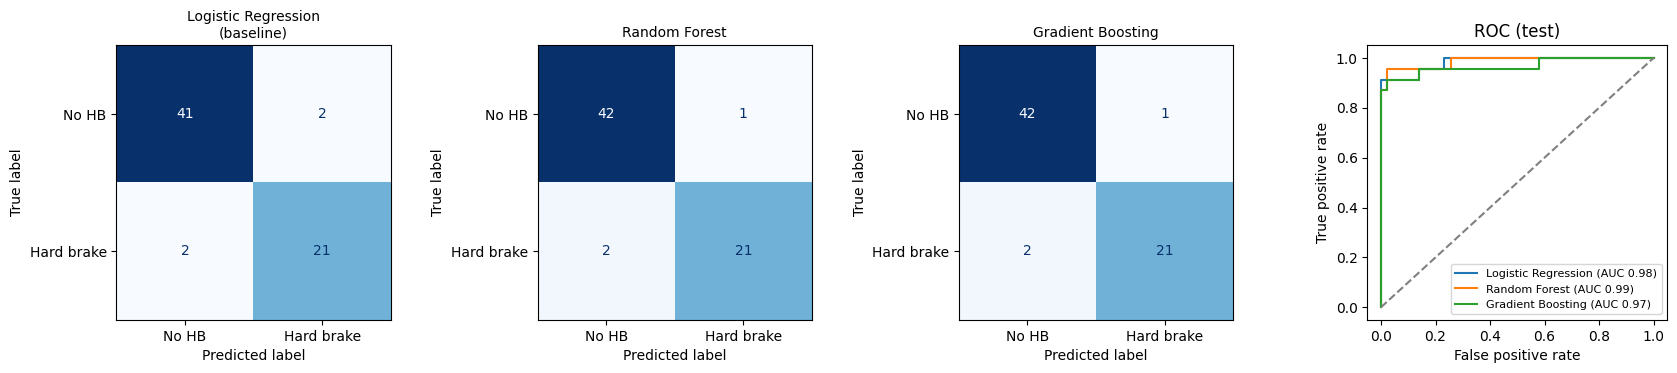

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, (name, m) in zip(axes[:3], models.items()):
    pred = (m.predict_proba(X_test)[:, 1] >= 0.5).astype(int)
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["No HB", "Hard brake"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name.replace(" (baseline)", "\n(baseline)"), fontsize=10)
    log(f"confusion matrix [{name}]: TN={cm[0, 0]} FP={cm[0, 1]} FN={cm[1, 0]} TP={cm[1, 1]}")
for name, m in models.items():
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    axes[3].plot(fpr, tpr, label=f"{name.split(' (')[0]} (AUC {test_table.loc[name, 'roc_auc']:.2f})")
axes[3].plot([0, 1], [0, 1], "--", color="gray")
axes[3].set_xlabel("False positive rate")
axes[3].set_ylabel("True positive rate")
axes[3].set_title("ROC (test)")
axes[3].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "05_confusion_roc.png", dpi=150)
plt.show()

### 9-2. 학습곡선 (Gradient Boosting)

트리를 더할수록 Train 손실은 계속 내려가지만 Validation 손실은 어느 지점부터 다시 올라간다. 그 지점이 과적합이 시작되는 곳이고, 세로 점선이 선택한 트리 개수다.

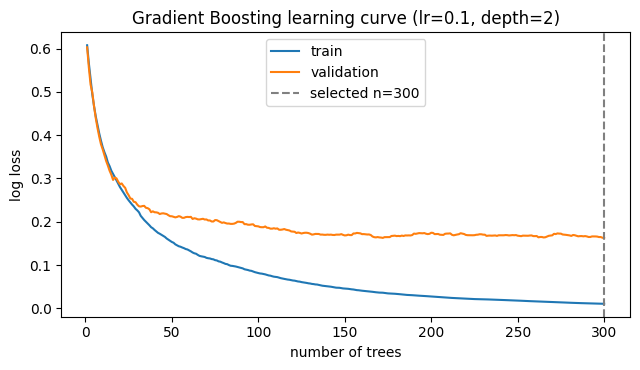

In [20]:
plt.figure(figsize=(6.5, 3.8))
x = np.arange(1, MAX_TREES + 1)
plt.plot(x, gb_best["tr_curve"], label="train")
plt.plot(x, gb_best["va_curve"], label="validation")
plt.axvline(gb_best["best_n"], ls="--", color="gray", label=f"selected n={gb_best['best_n']}")
plt.xlabel("number of trees")
plt.ylabel("log loss")
plt.title(f"Gradient Boosting learning curve (lr={gb_best['lr']}, depth={gb_best['depth']})")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "06_learning_curve.png", dpi=150)
plt.show()

### 9-3. 어떤 특징이 중요했나

최종 모델이 Test에서 각 특징을 얼마나 쓰는지 본다. 특징 하나의 값을 무작위로 섞었을 때 F1이 얼마나 떨어지는지로 잰다(순열 중요도).


[순열 중요도 상위 8개] (Random Forest, test)
dec_1s_min        0.136
acc_min           0.002
acc2s_min         0.000
acc_p05           0.000
hard_decel_sec    0.000
bp_p95            0.000
bp_max            0.000
bp_rise_02s       0.000


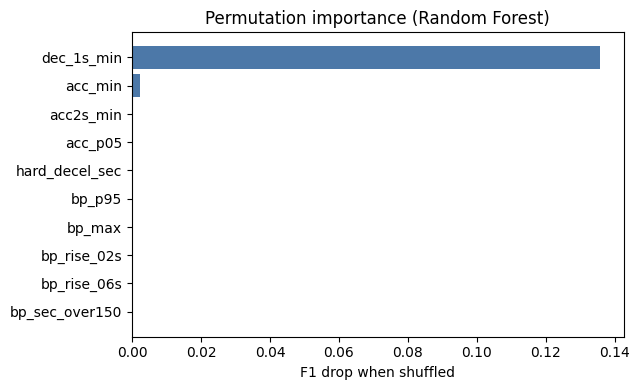

In [21]:
from sklearn.inspection import permutation_importance

pi = permutation_importance(final_model, X_test, y_test, scoring="f1", n_repeats=30, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False)
log(f"\n[순열 중요도 상위 8개] ({final_name}, test)")
log(imp.head(8).round(3).to_string())

plt.figure(figsize=(6.5, 4))
top = imp.head(10)[::-1]
plt.barh(top.index, top.values, color="#4C78A8")
plt.xlabel("F1 drop when shuffled")
plt.title(f"Permutation importance ({final_name.split(' (')[0]})")
plt.tight_layout()
plt.savefig(FIG_DIR / "07_feature_importance.png", dpi=150)
plt.show()

### 9-4. 오류 사례

최종 모델이 Test에서 틀린 클립을 모아 실제 속도 그래프와 함께 본다.

- **FN** (놓침): 실제는 급제동인데 없다고 예측
- **FP** (오경보): 실제는 급제동이 없는데 있다고 예측


[오류 사례] Random Forest: Test 66개 중 3개 오류 (FN 2, FP 1)
        driver_id     section event  label   prob  pred type  acc_min  dec_06s_min  bp_max  bp_sec_over100
clip_id                                                                                                   
02885      000017  차대사람및차대자전거   급정지      1  0.226     0   FN    -2.58        -3.21    14.0             0.0
02811      000025  차대사람및차대자전거   급감속      1  0.463     0   FN    -2.73        -4.63   206.0             2.2
03067      000025    차대차및차량단독    일반      0  0.582     1   FP    -3.59        -5.32    24.0             0.0

[거동 종류별 Test 정답률]
        mean  size
event             
급감속    0.955    22
급정지    0.000     1
급출발    1.000     1
일반     0.976    42


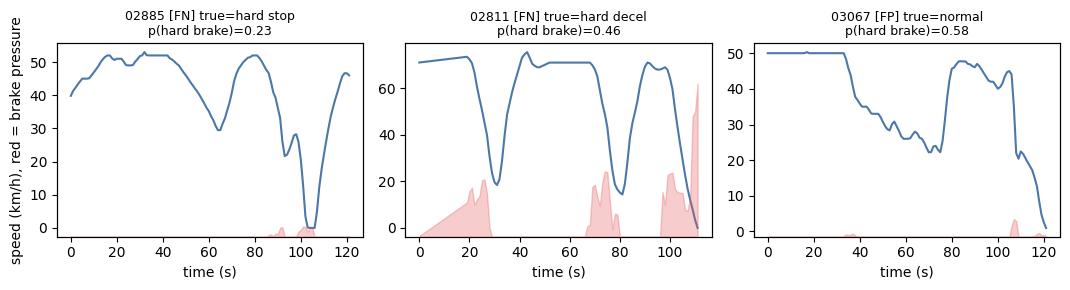

In [22]:
prob_test = final_model.predict_proba(X_test)[:, 1]
res = data.loc[X_test.index, ["driver_id", "section", "event", "label"]].copy()
res["prob"] = prob_test.round(3)
res["pred"] = (prob_test >= 0.5).astype(int)
res["type"] = np.where(res.label == res.pred, "OK", np.where(res.label == 1, "FN", "FP"))
errors = res[res["type"] != "OK"].copy()
errors = errors.join(data.loc[errors.index, ["acc_min", "dec_06s_min", "bp_max", "bp_sec_over100"]].round(2))

log(f"\n[오류 사례] {final_name}: Test {len(res)}개 중 {len(errors)}개 오류 (FN {(errors['type'] == 'FN').sum()}, FP {(errors['type'] == 'FP').sum()})")
log(errors.sort_values("prob").to_string())
log("\n[거동 종류별 Test 정답률]")
log(res.assign(correct=(res.label == res.pred)).groupby("event")["correct"].agg(["mean", "size"]).round(3).to_string())
errors.to_csv(OUT_DIR / "error_cases.csv", encoding="utf-8-sig")

show_ids = list(errors.sort_values("prob").index[:6])
if show_ids:
    fig, axes = plt.subplots(1, len(show_ids), figsize=(3.6 * len(show_ids), 3), squeeze=False)
    en = {"일반": "normal", "급감속": "hard decel", "급정지": "hard stop", "급출발": "hard launch", "급가속": "hard accel"}
    for ax, cid in zip(axes[0], show_ids):
        s = series[cid]
        ax.plot(s.index, s["speed"], color="#4C78A8", label="speed")
        ax2 = ax.twinx()
        ax2.fill_between(s.index, 0, s["brake_pressure"], color="#E45756", alpha=0.3)
        ax2.set_ylim(0, 260)
        ax2.set_yticks([])
        r = errors.loc[cid]
        ax.set_title(f"{cid} [{r['type']}] true={en[r['event']]}\np(hard brake)={r['prob']:.2f}", fontsize=9)
        ax.set_xlabel("time (s)")
    axes[0][0].set_ylabel("speed (km/h), red = brake pressure")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "08_error_cases.png", dpi=150)
    plt.show()
else:
    print("Test에서 틀린 클립이 없습니다.")

## 10. 최종 모델 저장

웹 서비스가 불러 쓸 수 있도록 최종 모델을 파일로 저장한다. 전처리(결측 대치, 스케일링)가 `Pipeline` 안에 들어 있어서 모델 파일 하나만 있으면 예측할 수 있다.

저장 후 **파일에서 다시 불러와** 예측이 같은지 확인하고, 원본 CAN 파일 → 전처리 → 특징 → 예측까지 서비스와 같은 흐름으로 한 번 돌려 본다.

In [23]:
MODEL_PATH = OUT_DIR / "hard_braking_model.joblib"
META_PATH = OUT_DIR / "model_meta.json"

joblib.dump(final_model, MODEL_PATH)
meta = {
    "model_name": final_name,
    "target": "hard braking (급감속 or 급정지) within a 2-minute clip",
    "features": FEATURES,
    "threshold": 0.5,
    "seed": SEED,
    "sklearn_version": sklearn.__version__,
    "n_train": int(len(X_train)), "n_val": int(len(X_val)), "n_test": int(len(X_test)),
    "fitted_on": "train+val",
    "dev_cv_metrics": {k: float(v) for k, v in cv_table.loc[final_name].items()},
    "test_metrics": {k: float(v) for k, v in test_table.loc[final_name].items()},
    "trained_at": time.strftime("%Y-%m-%d %H:%M:%S"),
}
META_PATH.write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")

loaded = joblib.load(MODEL_PATH)
same = np.allclose(loaded.predict_proba(X_test)[:, 1], prob_test)
print(f"모델 저장: {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1024:.0f} KB)")
print("다시 불러온 모델의 예측이 동일한가:", same)
assert same

def predict_clip(frames, model=loaded, features=FEATURES):
    """원본 CAN 프레임 -> 급제동 확률. 서비스 백엔드가 하게 될 일과 같다."""
    s1, s5, info = preprocess_frames(frames)
    x = pd.DataFrame([extract_features(s1, s5)])[features]
    return float(model.predict_proba(x)[0, 1]), info

for cid in list(X_test.index[:4]):
    p, info = predict_clip(read_frames(cid))
    print(f"  클립 {cid}: 실제={data.loc[cid, 'event']:<4} 급제동 확률={p:.3f} ({info['n_seconds']}초)")

log(f"\n모델 저장 완료: {MODEL_PATH.name} / {META_PATH.name}")

모델 저장: /content/drive/MyDrive/ml-final/outputs/hard_braking_model.joblib (938 KB)
다시 불러온 모델의 예측이 동일한가: True
  클립 02791: 실제=일반   급제동 확률=0.018 (122초)
  클립 02740: 실제=급출발  급제동 확률=0.170 (122초)
  클립 02690: 실제=일반   급제동 확률=0.010 (122초)
  클립 02739: 실제=일반   급제동 확률=0.245 (122초)

모델 저장 완료: hard_braking_model.joblib / model_meta.json


## 11. (선택) 실제 도로 클립에 적용

실제 도로 클립에는 급제동 정답이 없어서 성능을 잴 수는 없다. 대신 학습한 모델이 실제 도로 주행에서 급제동을 얼마나 잡아내는지 **분포만** 본다. 평범한 시내 주행이 대부분이므로 탐지 비율이 낮게 나와야 정상이다.

실제 도로 CAN zip(사고다발구간·사고위험구간·기타구간)을 올린 경우에만 실행된다. 2,300여 개를 읽으므로 몇 분 걸리고, 결과는 `features_real.csv`로 저장해 두어 다시 실행하면 바로 불러온다.

In [24]:
REAL_CACHE = OUT_DIR / "features_real.csv"
real_labels = labels[labels["scenario"] == "Real"].set_index("clip_id")

if REAL_CACHE.exists():
    real_feat = pd.read_csv(REAL_CACHE, dtype={"clip_id": str}).set_index("clip_id")
    print("저장해 둔 특징을 불러왔습니다:", len(real_feat), "개")
else:
    todo = [cid for cid in real_labels.index if cid in can_index]
    t0, rows_ = time.time(), []
    for i, cid in enumerate(todo):
        try:
            s1, s5, info = preprocess_frames(read_frames(cid))
            rows_.append({"clip_id": cid, **extract_features(s1, s5)})
        except Exception as e:                       # 깨진 파일이 있어도 멈추지 않는다
            print(f"  건너뜀 {cid}: {type(e).__name__} {e}")
        if (i + 1) % 200 == 0 or i + 1 == len(todo):
            print(f"  {i + 1}/{len(todo)} ({time.time() - t0:.0f}초)")
    real_feat = pd.DataFrame(rows_).set_index("clip_id") if rows_ else pd.DataFrame()
    if len(real_feat):
        real_feat.to_csv(REAL_CACHE, encoding="utf-8-sig")

HAS_REAL = len(real_feat) > 0
if not HAS_REAL:
    print("실제 도로 CAN zip이 없어 11단계는 건너뜁니다.")
else:
    real_feat = real_feat.loc[real_feat.index.intersection(real_labels.index)]
    real = real_labels.loc[real_feat.index].copy()
    print("\n[모델별 탐지 비율] 실제 도로 클립 %d개 (정답 없음)" % len(real))
    for name, m in models.items():
        p = m.predict_proba(real_feat[FEATURES])[:, 1]
        log(f"  real-road | {name:<32} 급제동으로 탐지 {(p >= 0.5).sum():>4}개 ({(p >= 0.5).mean():.1%}) | 확률 중앙값 {np.median(p):.3f}")

    real["prob"] = loaded.predict_proba(real_feat[FEATURES])[:, 1]
    real["flag"] = (real["prob"] >= 0.5).astype(int)
    print(f"\n[최종 모델: {final_name}] 구간별 탐지 비율")
    print(real.groupby("section")["flag"].agg(["mean", "sum", "size"]).round(3).to_string())
    print("\n[탐지 여부별 특징 중앙값]")
    cmp_ = real_feat.groupby(real["flag"])[["acc_min", "dec_06s_min", "bp_max", "bp_sec_over100"]].median().round(2)
    cmp_.index = cmp_.index.map({0: "실제 도로: 미탐지", 1: "실제 도로: 탐지"})
    ref = data.groupby("label")[["acc_min", "dec_06s_min", "bp_max", "bp_sec_over100"]].median().round(2)
    ref.index = ref.index.map({0: "테스트 도로: 급제동 없음", 1: "테스트 도로: 급제동"})
    print(pd.concat([cmp_, ref]).to_string())
    print("\n[급제동 확률 상위 10개 클립]")
    top = real.sort_values("prob", ascending=False).head(10)
    print(top[["section", "driver_id", "prob"]].join(real_feat[["acc_min", "dec_06s_min", "bp_max"]]).round(2).to_string())
    real[["section", "driver_id", "prob", "flag"]].to_csv(OUT_DIR / "real_road_predictions.csv", encoding="utf-8-sig")

    plt.figure(figsize=(6.5, 3.5))
    plt.hist(real["prob"], bins=30, color="#4C78A8")
    plt.axvline(0.5, ls="--", color="gray")
    plt.xlabel("predicted probability of hard braking")
    plt.ylabel("clips")
    plt.title("Real-road clips (no ground truth)")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "09_real_road_distribution.png", dpi=150)
    plt.show()

실제 도로 CAN zip이 없어 11단계는 건너뜁니다.


### 11-1. 지름길 학습 확인 실험

2-1에서 "급출발까지 정답에 넣고 맥락 값(정지 비율, 출발 세기 등)까지 특징으로 쓰면 지름길을 배운다"고 했다. 실제로 그런지 같은 분할(Train+Validation으로 학습, Test로 평가)로 **비교용 모델**을 하나 만들어 확인한다. 이 모델은 확인용일 뿐 저장하거나 서비스에 쓰지 않는다.

- 비교용: 정답 = 급거동 전체(급감속·급정지·급출발·급가속), 특징 = 제동 특징 + 맥락 값, Gradient Boosting
- 볼 것: 테스트 도로 Test 점수는 높은데 실제 도로에서 탐지 비율이 비정상적으로 높은가

In [25]:
if HAS_REAL:
    y_any = (data["event"] != "일반").astype(int)
    feats_sc = FEATURES + CONTEXT
    tr_idx, te_idx = data.index[data.split != "test"], data.index[data.split == "test"]
    shortcut = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("clf", GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=3,
                                           subsample=0.8, random_state=SEED)),
    ]).fit(data.loc[tr_idx, feats_sc], y_any.loc[tr_idx])
    sc_test = evaluate(shortcut, data.loc[te_idx, feats_sc], y_any.loc[te_idx])
    p_sc = shortcut.predict_proba(real_feat[feats_sc])[:, 1]
    imp_sc = pd.Series(shortcut["clf"].feature_importances_, index=feats_sc).sort_values(ascending=False)

    log("\n[지름길 학습 확인]")
    log(f"  비교용(급거동 전체 + 맥락 값): Test F1={sc_test['f1']:.3f} | 실제 도로 탐지 비율 {(p_sc >= 0.5).mean():.1%}")
    log(f"  최종 모델(급제동 + 제동 특징) : Test F1={test_table.loc[final_name, 'f1']:.3f} | 실제 도로 탐지 비율 {real['flag'].mean():.1%}")
    log("  비교용 모델의 중요 특징 상위 5개: " + ", ".join(f"{k}({v:.2f})" for k, v in imp_sc.head(5).items()))
    flagged = p_sc >= 0.5
    log(f"  비교용 모델이 탐지한 실제 도로 클립의 1초 최대 감속 중앙값: {real_feat.loc[flagged, 'acc_min'].median():.2f} m/s^2"
        f" (테스트 도로 급제동 클립은 {data.loc[data.label == 1, 'acc_min'].median():.2f})")
else:
    print("실제 도로 데이터가 없어 건너뜁니다.")

실제 도로 데이터가 없어 건너뜁니다.


## 결과물 정리

이 노트북을 끝까지 실행하면 `ml-final/outputs`에 아래 파일이 생긴다.

| 파일 | 용도 |
|---|---|
| `hard_braking_model.joblib`, `model_meta.json` | 웹 서비스가 불러 쓸 모델과 설정 |
| `train_log.txt` | 학습 로그 |
| `test_metrics.csv`, `val_metrics.csv`, `cv_metrics.csv` | README 비교표 (Test / Validation / 개발 세트 교차검증) |
| `error_cases.csv` | 오류 사례 분석 |
| `figures/*.png` | README에 넣을 그래프 |
| `labels.csv`, `features_*.csv`, `split.csv` | 재현용 중간 결과 (AI Hub 데이터에서 만든 것이므로 GitHub에는 올리지 않는다) |

In [26]:
print("저장된 결과물")
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file():
        print(f"  {str(p.relative_to(OUT_DIR)):<40} {p.stat().st_size / 1024:>8.1f} KB")

저장된 결과물
  cv_metrics.csv                                0.2 KB
  error_cases.csv                               0.3 KB
  features_study.csv                          116.5 KB
  figures/01_class_distribution.png            45.3 KB
  figures/02_sensor_quality.png                42.1 KB
  figures/03_cleaning_before_after.png         57.6 KB
  figures/04_feature_boxplots.png              45.2 KB
  figures/05_confusion_roc.png                 81.2 KB
  figures/06_learning_curve.png                54.2 KB
  figures/07_feature_importance.png            42.3 KB
  figures/08_error_cases.png                   92.8 KB
  hard_braking_model.joblib                   937.6 KB
  labels.csv                                 1536.4 KB
  model_meta.json                               0.9 KB
  split.csv                                     9.2 KB
  test_metrics.csv                              0.2 KB
  train_log.txt                                 6.3 KB
  val_metrics.csv                               0.2 KB
